In [2]:
from Bio.PDB import PDBParser

parser = PDBParser(QUIET=True)

apo = parser.get_structure("apo", "9nps.pdb")
bound = parser.get_structure("bound", "9NPR.pdb")

APO_MODEL = apo[0]
BOUND_MODEL = bound[0]

GP1_CHAINS = ["A","B","C"]
GP2_CHAINS = ["D","E","F"]
NPC1_CHAINS = ["G","H","I"]

In [3]:
from Bio.PDB import Superimposer

def get_ca_atoms(model, chains):
    atoms = []

    for chain_id in chains:
        chain = model[chain_id]

        for res in chain:
            if res.id[0] == " " and "CA" in res:
                atoms.append(res["CA"])

    return atoms

apo_ca = get_ca_atoms(APO_MODEL, GP1_CHAINS + GP2_CHAINS)
bound_ca = get_ca_atoms(BOUND_MODEL, GP1_CHAINS + GP2_CHAINS)

n = min(len(apo_ca), len(bound_ca))

sup = Superimposer()
sup.set_atoms(apo_ca[:n], bound_ca[:n])

print("RMSD:", sup.rms)

sup.apply(BOUND_MODEL.get_atoms())

RMSD: 30.099583103245234


In [4]:
def find_numbering_gaps(chain):

    nums = sorted(
        res.id[1]
        for res in chain
        if res.id[0] == " "
    )

    gaps = []

    for i in range(len(nums)-1):

        start = nums[i]
        end = nums[i+1]

        if end - start > 1:

            gaps.append(
                (
                    start+1,
                    end-1,
                    end-start-1
                )
            )

    return gaps

In [5]:
for chain_id in GP1_CHAINS + GP2_CHAINS:

    gaps = find_numbering_gaps(APO_MODEL[chain_id])

    print(chain_id, gaps)

A [(181, 206, 26)]
B [(479, 488, 10), (495, 509, 15)]
C []
D [(479, 488, 10), (495, 509, 15)]
E []
F [(477, 488, 12), (495, 509, 15)]


In [6]:
from Bio.PDB import NeighborSearch

def get_chain_atoms(model, chains):

    atoms = []

    for ch in chains:

        chain = model[ch]

        for atom in chain.get_atoms():

            if atom.element != "H":
                atoms.append(atom)

    return atoms

In [7]:
gp_atoms = get_chain_atoms(
    BOUND_MODEL,
    GP1_CHAINS + GP2_CHAINS
)

npc1_atoms = get_chain_atoms(
    BOUND_MODEL,
    NPC1_CHAINS
)

ns = NeighborSearch(npc1_atoms)

interface = set()

for atom in gp_atoms:

    neighbors = ns.search(atom.coord, 4.5)

    if neighbors:

        res = atom.get_parent()
        chain = res.get_parent().id

        interface.add(
            (
                chain,
                res.id[1],
                res.get_resname()
            )
        )

print("Interface residues:", len(interface))

Interface residues: 75


In [8]:
def extract_contacts(model, chains, cutoff=8.0):

    contacts = set()

    residues = []

    for ch in chains:

        chain = model[ch]

        for res in chain:

            if res.id[0] == " " and "CA" in res:

                residues.append(
                    (
                        ch,
                        res.id[1],
                        res["CA"]
                    )
                )

    N = len(residues)

    for i in range(N):

        ch_i, num_i, ca_i = residues[i]

        for j in range(i+1, N):

            ch_j, num_j, ca_j = residues[j]

            if ch_i == ch_j:
                if abs(num_i-num_j) <= 3:
                    continue

            if (ca_i-ca_j) < cutoff:

                contacts.add(
                    (
                        ch_i,
                        num_i,
                        ch_j,
                        num_j
                    )
                )

    return contacts

In [9]:
apo_contacts = extract_contacts(
    APO_MODEL,
    GP1_CHAINS + GP2_CHAINS
)

bound_contacts = extract_contacts(
    BOUND_MODEL,
    GP1_CHAINS + GP2_CHAINS
)

In [10]:
shared = apo_contacts & bound_contacts

union = apo_contacts | bound_contacts

Q_overlap = len(shared) / len(union)

print(Q_overlap)

0.2901669758812616


In [11]:
from collections import defaultdict

contact_change = defaultdict(int)

for c in (apo_contacts - bound_contacts):

    ch1,n1,ch2,n2 = c

    contact_change[(ch1,n1)] -= 1
    contact_change[(ch2,n2)] -= 1

for c in (bound_contacts - apo_contacts):

    ch1,n1,ch2,n2 = c

    contact_change[(ch1,n1)] += 1
    contact_change[(ch2,n2)] += 1

In [13]:
ranked = sorted(
    contact_change.items(),
    key=lambda x: abs(x[1]),
    reverse=True
)

for item in ranked[:20]:
    print(item)

(('E', 146), -10)
(('E', 164), -10)
(('E', 165), -10)
(('E', 166), -10)
(('E', 51), -10)
(('E', 167), -10)
(('B', 169), 10)
(('B', 161), 10)
(('B', 164), 10)
(('B', 51), 10)
(('B', 52), 10)
(('B', 165), 10)
(('E', 145), -9)
(('E', 52), -9)
(('E', 85), -9)
(('B', 556), -9)
(('E', 79), -9)
(('E', 83), -9)
(('E', 137), -9)
(('B', 519), -9)


In [14]:
displacements = []

for chain_id in GP1_CHAINS + GP2_CHAINS:

    chain_apo = APO_MODEL[chain_id]
    chain_bound = BOUND_MODEL[chain_id]

    for res in chain_apo:

        if res.id[0] != " ":
            continue

        if "CA" not in res:
            continue

        if res.id not in chain_bound:
            continue

        res_bound = chain_bound[res.id]

        if "CA" not in res_bound:
            continue

        disp = (
            res["CA"] -
            res_bound["CA"]
        )

        displacements.append(
            (
                chain_id,
                res.id[1],
                disp
            )
        )

In [15]:
with open("native_contacts_apo.dat","w") as f:

    for ch1,n1,ch2,n2 in sorted(apo_contacts):

        f.write(
            f"{ch1} {n1} {ch2} {n2}\n"
        )

In [16]:
from collections import defaultdict

loss = defaultdict(int)
gain = defaultdict(int)

for c in apo_contacts - bound_contacts:

    ch1,n1,ch2,n2 = c

    loss[(ch1,n1)] += 1
    loss[(ch2,n2)] += 1

for c in bound_contacts - apo_contacts:

    ch1,n1,ch2,n2 = c

    gain[(ch1,n1)] += 1
    gain[(ch2,n2)] += 1

In [17]:
sorted(loss.items(),
       key=lambda x:x[1],
       reverse=True)[:20]

[(('E', 146), 10),
 (('E', 164), 10),
 (('E', 165), 10),
 (('E', 166), 10),
 (('E', 51), 10),
 (('E', 167), 10),
 (('E', 145), 9),
 (('E', 52), 9),
 (('E', 85), 9),
 (('B', 556), 9),
 (('E', 79), 9),
 (('E', 83), 9),
 (('E', 137), 9),
 (('B', 519), 9),
 (('E', 144), 9),
 (('E', 161), 9),
 (('E', 50), 9),
 (('E', 159), 9),
 (('E', 98), 8),
 (('E', 163), 8)]

In [19]:
sorted(gain.items(),
       key=lambda x:x[1],
       reverse=True)[:20]

[(('B', 169), 10),
 (('B', 161), 10),
 (('B', 164), 10),
 (('B', 51), 10),
 (('B', 52), 10),
 (('B', 165), 10),
 (('B', 85), 9),
 (('B', 143), 9),
 (('B', 145), 9),
 (('B', 138), 9),
 (('B', 152), 9),
 (('B', 80), 9),
 (('E', 519), 9),
 (('B', 135), 9),
 (('B', 146), 9),
 (('B', 144), 9),
 (('B', 79), 9),
 (('B', 166), 9),
 (('B', 137), 9),
 (('B', 153), 9)]

In [21]:
from Bio.PDB import Superimposer

def get_matching_calpha_pairs(model1, model2, chains):
    atoms1 = []
    atoms2 = []

    for chain_id in chains:

        if chain_id not in model1:
            continue

        if chain_id not in model2:
            continue

        chain1 = model1[chain_id]
        chain2 = model2[chain_id]

        res_ids_1 = {
            res.id
            for res in chain1
            if res.id[0] == " " and "CA" in res
        }

        res_ids_2 = {
            res.id
            for res in chain2
            if res.id[0] == " " and "CA" in res
        }

        common_residues = sorted(
            res_ids_1.intersection(res_ids_2),
            key=lambda x: x[1]
        )

        for rid in common_residues:

            atoms1.append(chain1[rid]["CA"])
            atoms2.append(chain2[rid]["CA"])

    return atoms1, atoms2


apo_atoms, bound_atoms = get_matching_calpha_pairs(
    APO_MODEL,
    BOUND_MODEL,
    GP1_CHAINS + GP2_CHAINS
)

print("Matched residues:", len(apo_atoms))

sup = Superimposer()
sup.set_atoms(apo_atoms, bound_atoms)

print("RMSD (matched residues):", sup.rms)

sup.apply(BOUND_MODEL.get_atoms())

Matched residues: 483
RMSD (matched residues): 22.18710991897702


In [22]:
import pandas as pd
from collections import defaultdict

delta_contacts = defaultdict(int)

for c in apo_contacts - bound_contacts:

    ch1,n1,ch2,n2 = c

    delta_contacts[(ch1,n1)] -= 1
    delta_contacts[(ch2,n2)] -= 1

for c in bound_contacts - apo_contacts:

    ch1,n1,ch2,n2 = c

    delta_contacts[(ch1,n1)] += 1
    delta_contacts[(ch2,n2)] += 1

rows = []

for (chain,resnum),delta in delta_contacts.items():

    rows.append(
        [
            chain,
            resnum,
            delta
        ]
    )

df_delta = pd.DataFrame(
    rows,
    columns=[
        "Chain",
        "Residue",
        "DeltaContacts"
    ]
)

df_delta["AbsDelta"] = df_delta["DeltaContacts"].abs()

df_delta.sort_values(
    "AbsDelta",
    ascending=False
).to_csv(
    "per_residue_contact_change.csv",
    index=False
)

print(
    df_delta.sort_values(
        "AbsDelta",
        ascending=False
    ).head(20)
)


    Chain  Residue  DeltaContacts  AbsDelta
100     E      164            -10        10
286     E      167            -10        10
85      E      146            -10        10
706     B       52             10        10
565     B      169             10        10
168     E      165            -10        10
610     B      164             10        10
611     B       51             10        10
744     B      165             10        10
280     E       51            -10        10
587     B      161             10        10
249     E      166            -10        10
15      E      145             -9         9
16      E       52             -9         9
669     B       53              9         9
172     E      137             -9         9
196     E      161             -9         9
571     B      138              9         9
581     B       80              9         9
585     B      135              9         9



New contacts formed : 5960
Contacts destroyed  : 11932


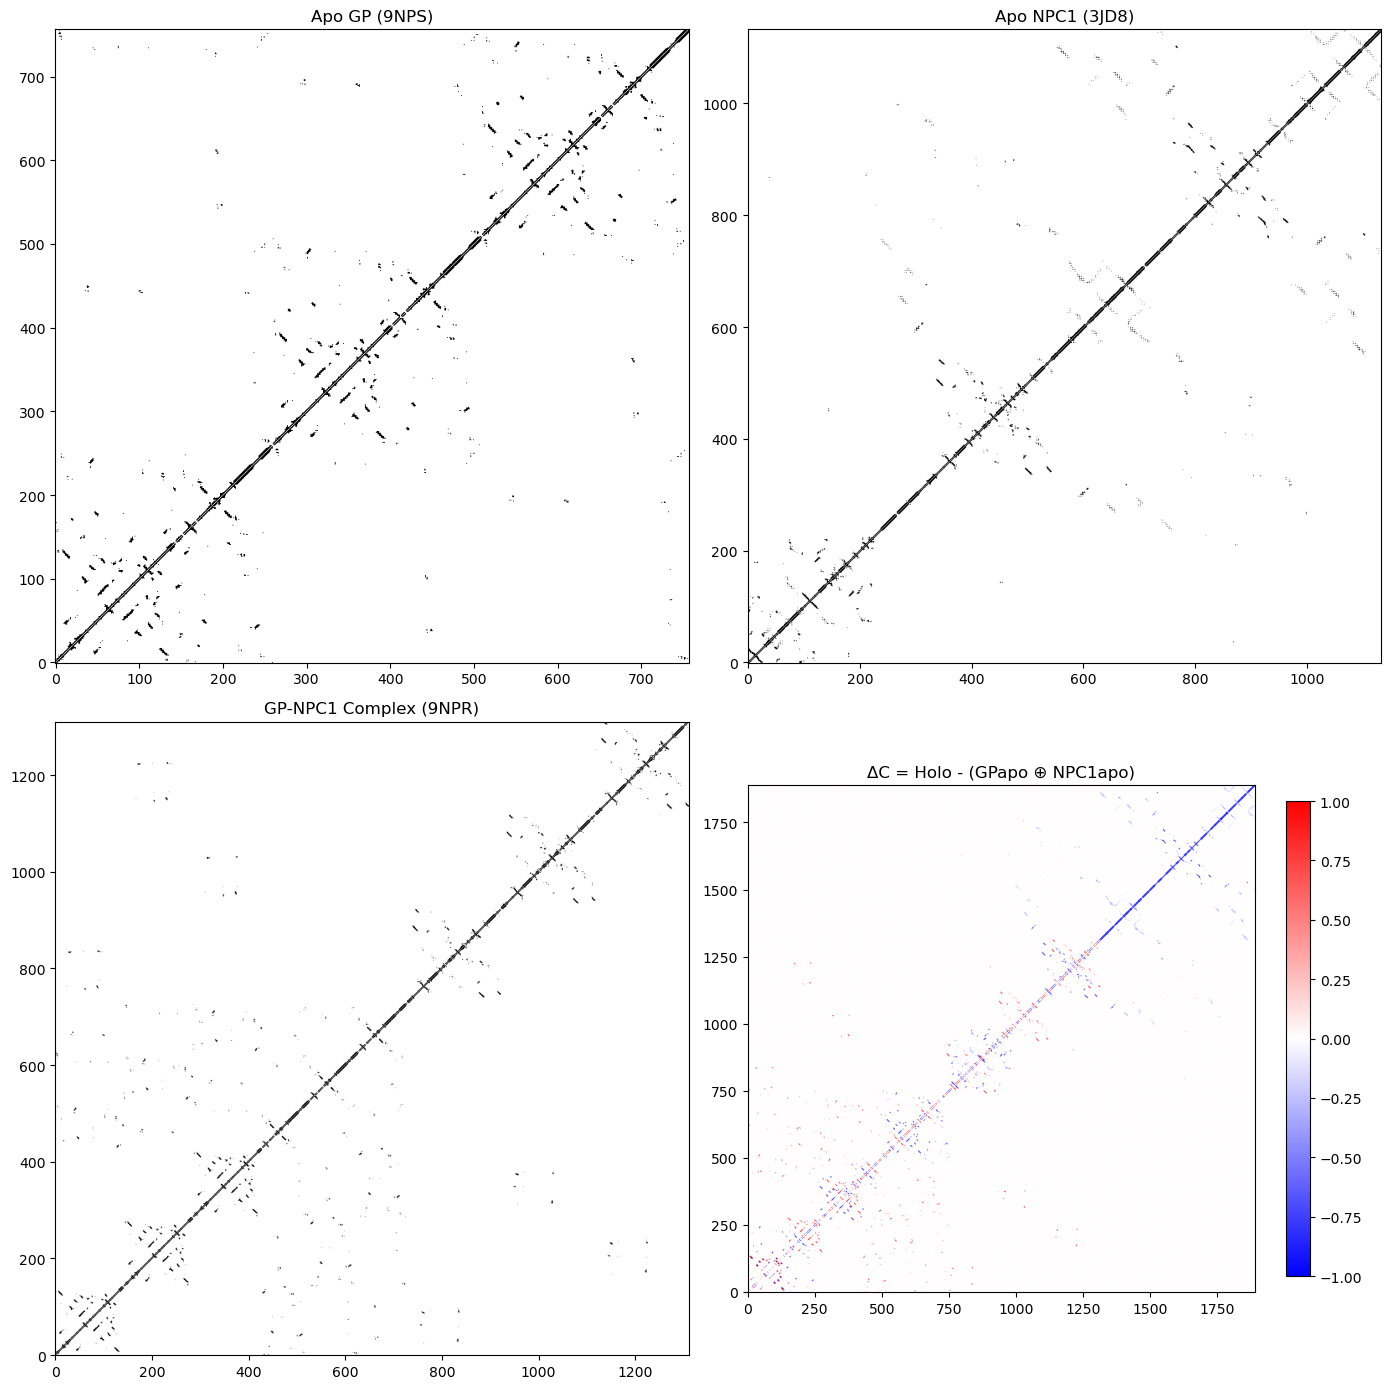

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import block_diag
from Bio.PDB import PDBParser

##############################################################################
# FILES
##############################################################################

GP_APO_PDB   = "9nps.pdb"   # apo GP
NPC1_APO_PDB = "3JD8.pdb"   # apo NPC1
HOLO_PDB     = "9NPR.pdb"   # GP-NPC1 complex

##############################################################################
# CHAIN DEFINITIONS
##############################################################################

GP_CHAINS_HOLO = ["A","B","C","D","E","F"]
NPC1_CHAINS_HOLO = ["G","H","I"]

# 3JD8
NPC1_APO_CHAINS = ["A"]

##############################################################################
# LOAD STRUCTURES
##############################################################################

parser = PDBParser(QUIET=True)

gp_apo = parser.get_structure("gpapo", GP_APO_PDB)[0]
npc1_apo = parser.get_structure("npc1apo", NPC1_APO_PDB)[0]
holo = parser.get_structure("holo", HOLO_PDB)[0]

##############################################################################
# EXTRACT CA COORDINATES
##############################################################################

def extract_ca_coordinates(model, chains):

    coords = []

    for chain_id in chains:

        if chain_id not in model:
            continue

        chain = model[chain_id]

        for res in chain:

            if res.id[0] != " ":
                continue

            if "CA" not in res:
                continue

            coords.append(res["CA"].coord)

    return np.array(coords)

##############################################################################
# CONTACT MATRIX
##############################################################################

def build_contact_matrix(coords, cutoff=8.0):

    n = len(coords)

    M = np.zeros((n,n), dtype=np.int8)

    for i in range(n):

        d = coords - coords[i]

        dist = np.sqrt(np.sum(d*d, axis=1))

        mask = dist < cutoff

        M[i,mask] = 1

    np.fill_diagonal(M,0)

    return M

##############################################################################
# BUILD MATRICES
##############################################################################

gp_apo_coords = extract_ca_coordinates(
    gp_apo,
    ["A","B","C","D","E","F"]
)

npc1_apo_coords = extract_ca_coordinates(
    npc1_apo,
    NPC1_APO_CHAINS
)

holo_coords = extract_ca_coordinates(
    holo,
    GP_CHAINS_HOLO + NPC1_CHAINS_HOLO
)

C_GP_APO = build_contact_matrix(gp_apo_coords)

C_NPC1_APO = build_contact_matrix(npc1_apo_coords)

C_HOLO = build_contact_matrix(holo_coords)

##############################################################################
# BLOCK-DIAGONAL APO REFERENCE
##############################################################################

C_APO_REFERENCE = block_diag(
    C_GP_APO,
    C_NPC1_APO
)

##############################################################################
# MATCH SIZES
##############################################################################

N = max(
    C_APO_REFERENCE.shape[0],
    C_HOLO.shape[0]
)

def pad(M,n):

    out = np.zeros((n,n))

    out[:M.shape[0], :M.shape[1]] = M

    return out

C_APO_REFERENCE = pad(
    C_APO_REFERENCE,
    N
)

C_HOLO_PAD = pad(
    C_HOLO,
    N
)

##############################################################################
# DIFFERENCE MATRIX
##############################################################################

DELTA = C_HOLO_PAD - C_APO_REFERENCE

##############################################################################
# COUNTS
##############################################################################

gained = np.sum(DELTA > 0)
lost   = np.sum(DELTA < 0)

print()
print("New contacts formed :", gained)
print("Contacts destroyed  :", lost)

##############################################################################
# PLOTS
##############################################################################

fig, ax = plt.subplots(
    2,
    2,
    figsize=(14,14)
)

ax[0,0].imshow(
    C_GP_APO,
    cmap="Greys",
    origin="lower"
)

ax[0,0].set_title(
    "Apo GP (9NPS)"
)

ax[0,1].imshow(
    C_NPC1_APO,
    cmap="Greys",
    origin="lower"
)

ax[0,1].set_title(
    "Apo NPC1 (3JD8)"
)

ax[1,0].imshow(
    C_HOLO,
    cmap="Greys",
    origin="lower"
)

ax[1,0].set_title(
    "GP-NPC1 Complex (9NPR)"
)

im = ax[1,1].imshow(
    DELTA,
    cmap="bwr",
    origin="lower",
    vmin=-1,
    vmax=1
)

ax[1,1].set_title(
    "ΔC = Holo - (GPapo ⊕ NPC1apo)"
)

plt.colorbar(
    im,
    ax=ax[1,1],
    shrink=0.75
)

plt.tight_layout()
plt.show()